# Detecção de Fraude em Cartão de Crédito

Projeto do desafio DIO: treinar modelos que detectam fraude em transações reais de cartão, num cenário em que **só ~0,17% das transações são fraude**.

**Pergunta central:** como avaliar um modelo quando "chutar que nada é fraude" já acerta 99,8% das vezes?

## 0. Configuração

In [25]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, recall_score, precision_score, f1_score,
    roc_auc_score, average_precision_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, precision_recall_curve,
)

from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE
import shap

RANDOM_STATE = 42
pd.set_option("display.float_format", "{:.4f}".format)
plt.rcParams["figure.dpi"] = 110

print("Bibliotecas carregadas")


Bibliotecas carregadas


## 1. Explorar

O dataset é carregado **direto pelo link**, sem ficar no repositório (~150 MB). As colunas `V1` a `V28` vêm transformadas por PCA para proteger a privacidade. Só `Time` e `Amount` estão na escala original.

In [26]:
DATA_URL = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"

df = pd.read_csv(DATA_URL)

print(f"Linhas: {df.shape[0]:,} | Colunas: {df.shape[1]}")
df.head()

Linhas: 284,807 | Colunas: 31


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0000,-1.3598,-0.0728,2.5363,1.3782,-0.3383,0.4624,0.2396,0.0987,0.3638,...,-0.0183,0.2778,-0.1105,0.0669,0.1285,-0.1891,0.1336,-0.0211,149.6200,0
1,0.0000,1.1919,0.2662,0.1665,0.4482,0.0600,-0.0824,-0.0788,0.0851,-0.2554,...,-0.2258,-0.6387,0.1013,-0.3398,0.1672,0.1259,-0.0090,0.0147,2.6900,0
2,1.0000,-1.3584,-1.3402,1.7732,0.3798,-0.5032,1.8005,0.7915,0.2477,-1.5147,...,0.2480,0.7717,0.9094,-0.6893,-0.3276,-0.1391,-0.0554,-0.0598,378.6600,0
3,1.0000,-0.9663,-0.1852,1.7930,-0.8633,-0.0103,1.2472,0.2376,0.3774,-1.3870,...,-0.1083,0.0053,-0.1903,-1.1756,0.6474,-0.2219,0.0627,0.0615,123.5000,0
4,2.0000,-1.1582,0.8777,1.5487,0.4030,-0.4072,0.0959,0.5929,-0.2705,0.8177,...,-0.0094,0.7983,-0.1375,0.1413,-0.2060,0.5023,0.2194,0.2152,69.9900,0


In [27]:
print("Tipos de coluna:")
print(df.dtypes.value_counts())

print("\nValores nulos no total:", df.isnull().sum().sum())
print("Linhas duplicadas:", df.duplicated().sum())

df[["Time", "Amount"]].describe()

Tipos de coluna:
float64    30
int64       1
Name: count, dtype: int64

Valores nulos no total: 0
Linhas duplicadas: 1081


,Time,Amount
count,284807.0000,284807.0000
mean,94813.8596,88.3496
std,47488.1460,250.1201
min,0.0000,0.0000
25%,54201.5000,5.6000
50%,84692.0000,22.0000
75%,139320.5000,77.1650
max,172792.0000,25691.1600


In [28]:
contagem = df["Class"].value_counts()
proporcao = df["Class"].value_counts(normalize=True) * 100

tabela_classes = pd.DataFrame({"quantidade": contagem, "% do total": proporcao})
tabela_classes.index = ["0 = normal", "1 = fraude"]

print(f"Acurácia de quem chuta 'nunca é fraude': {proporcao[0]:.2f}%")
tabela_classes

Acurácia de quem chuta 'nunca é fraude': 99.83%


,quantidade,% do total
0 = normal,284315,99.8273
1 = fraude,492,0.1727


**A armadilha da acurácia:** um "modelo" que responde sempre "normal" acerta **99,83%** e não pega nenhuma das 492 fraudes. Por isso a avaliação deste projeto usa **recall, precisão, F1 e PR-AUC da classe fraude**, e não a acurácia.

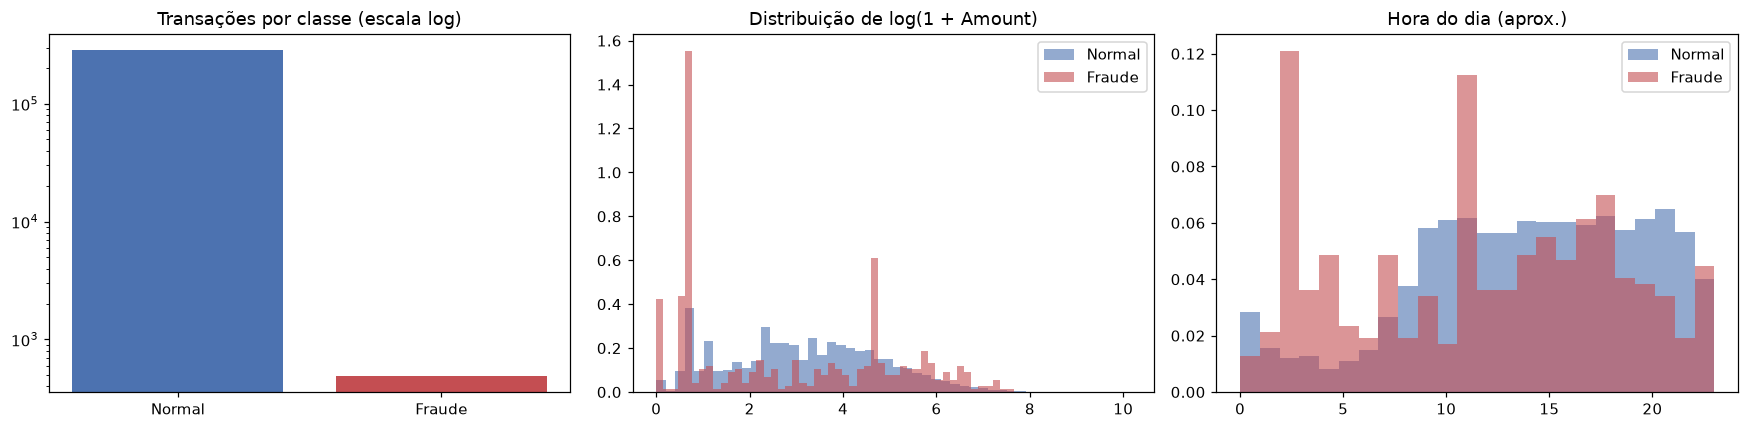

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].bar(["Normal", "Fraude"], contagem.values, color=["#4C72B0", "#C44E52"])
axes[0].set_yscale("log")
axes[0].set_title("Transações por classe (escala log)")

for classe, cor, rotulo in [(0, "#4C72B0", "Normal"), (1, "#C44E52", "Fraude")]:
    valores = np.log1p(df.loc[df["Class"] == classe, "Amount"])
    axes[1].hist(valores, bins=50, density=True, alpha=0.6, color=cor, label=rotulo)
axes[1].set_title("Distribuição de log(1 + Amount)")
axes[1].legend()

hora = (df["Time"] // 3600) % 24
for classe, cor, rotulo in [(0, "#4C72B0", "Normal"), (1, "#C44E52", "Fraude")]:
    axes[2].hist(hora[df["Class"] == classe], bins=24, density=True, alpha=0.6, color=cor, label=rotulo)
axes[2].set_title("Hora do dia (aprox.)")
axes[2].legend()

plt.tight_layout()
plt.show()

**Leitura dos gráficos:**
- As fraudes se concentram em **valores muito baixos** (~1, típico de "teste de cartão"), em valor 0 e em ~99. As normais formam uma distribuição mais suave.
- As fraudes são proporcionalmente mais comuns na **madrugada** (picos nas horas 2 e 11). A hora é aproximada, porque a base não informa o horário real da primeira transação.
- Isso motiva as variáveis `Amount_log` e `Hour`, criadas na preparação.

## 2. Preparar

| Decisão | Por quê |
|---|---|
| Remover 1.081 linhas duplicadas | Uma cópia no treino e outra no teste faria o modelo "acertar de cor" e inflaria as métricas |
| `Amount_log = log1p(Amount)` | Reduz a assimetria do valor (o `log1p` aceita valor 0) |
| `Hour = (Time // 3600) % 24` | Transforma segundos corridos em hora do dia |
| `Time` e `Amount` removidas de `X` | Foram substituídas pelas versões transformadas |

In [30]:
dados = df.drop_duplicates().copy()
print(f"Removidas {len(df) - len(dados):,} linhas duplicadas")

dados["Amount_log"] = np.log1p(dados["Amount"])
dados["Hour"] = (dados["Time"] // 3600) % 24

X = dados.drop(columns=["Class", "Time", "Amount"])
y = dados["Class"]

print(f"X: {X.shape} | y: {y.shape}")
print("Fraudes restantes:", y.sum())

Removidas 1,081 linhas duplicadas
X: (283726, 30) | y: (283726,)
Fraudes restantes: 473


**Divisão em três conjuntos (60/20/20), todos com `stratify`:**

- **Treino:** o modelo aprende.
- **Validação:** escolhemos o limiar de decisão e o modelo final.
- **Teste:** fica intocado até o fim, para dar uma nota honesta.

Escolher o limiar olhando o teste deixaria a nota final otimista, porque o teste teria sido usado para tomar decisões.

In [31]:
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=RANDOM_STATE
)

pd.DataFrame({
    "linhas": [len(y_train), len(y_val), len(y_test)],
    "fraudes": [y_train.sum(), y_val.sum(), y_test.sum()],
    "% fraude": [y_train.mean() * 100, y_val.mean() * 100, y_test.mean() * 100],
}, index=["treino", "validação", "teste"])

,linhas,fraudes,% fraude
treino,170235,284,0.1668
validação,56745,94,0.1657
teste,56746,95,0.1674


## 3. Treinar

Uma função de avaliação única, usada em todos os modelos, garante uma comparação justa:

- **Recall (fraude):** das fraudes reais, quantas o modelo pegou. **Métrica principal**, porque fraude perdida é prejuízo.
- **Precisão (fraude):** dos alertas, quantos eram fraude de verdade. Alerta falso é cliente bloqueado à toa.
- **F1:** equilíbrio entre recall e precisão.
- **PR-AUC:** qualidade do ranking de probabilidades, sem depender de limiar. Mais informativa que a ROC-AUC em base desbalanceada.

In [32]:
def avaliar(nome, y_true, proba, limiar=0.5):
    pred = (proba >= limiar).astype(int)
    return {
        "modelo": nome,
        "limiar": limiar,
        "recall": recall_score(y_true, pred),
        "precisão": precision_score(y_true, pred, zero_division=0),
        "f1": f1_score(y_true, pred, zero_division=0),
        "pr_auc": average_precision_score(y_true, proba),
        "roc_auc": roc_auc_score(y_true, proba),
        "acurácia": accuracy_score(y_true, pred),
    }

In [33]:
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)

proba_dummy = dummy.predict_proba(X_test)[:, 1]

pd.DataFrame([avaliar("Dummy (sempre normal)", y_test, proba_dummy)])

,modelo,limiar,recall,precisão,f1,pr_auc,roc_auc,acurácia
0,Dummy (sempre normal),0.5000,0.0000,0.0000,0.0000,0.0017,0.5000,0.9983


In [34]:
neg, pos = np.bincount(y_train)
peso_fraude = neg / pos
print(f"Para cada fraude há ~{peso_fraude:.0f} transações normais no treino")

modelos = {
    "Regressão Logística": Pipeline([
        ("scaler", StandardScaler()),
        ("modelo", LogisticRegression(class_weight="balanced", max_iter=1000,
                                      random_state=RANDOM_STATE)),
    ]),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, min_samples_leaf=2, class_weight="balanced_subsample",
        n_jobs=-1, random_state=RANDOM_STATE),
    "XGBoost": XGBClassifier(
        n_estimators=300, max_depth=4, learning_rate=0.1,
        subsample=0.8, colsample_bytree=0.8, scale_pos_weight=peso_fraude,
        eval_metric="aucpr", tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE),
}

proba_val, proba_test = {}, {}
for nome, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    proba_val[nome] = modelo.predict_proba(X_val)[:, 1]
    proba_test[nome] = modelo.predict_proba(X_test)[:, 1]
    print(f"{nome}: treinado")

Para cada fraude há ~598 transações normais no treino
Regressão Logística: treinado
Random Forest: treinado
XGBoost: treinado


In [35]:
resultados_05 = pd.DataFrame([avaliar(nome, y_test, proba) for nome, proba in proba_test.items()])
resultados_05.set_index("modelo")

,limiar,recall,precisão,f1,pr_auc,roc_auc,acurácia
modelo,,,,,,,
Regressão Logística,0.5000,0.8737,0.0496,0.0938,0.6796,0.9611,0.9718
Random Forest,0.5000,0.7053,0.9710,0.8171,0.8068,0.9380,0.9995
XGBoost,0.5000,0.7895,0.9259,0.8523,0.8280,0.9716,0.9995


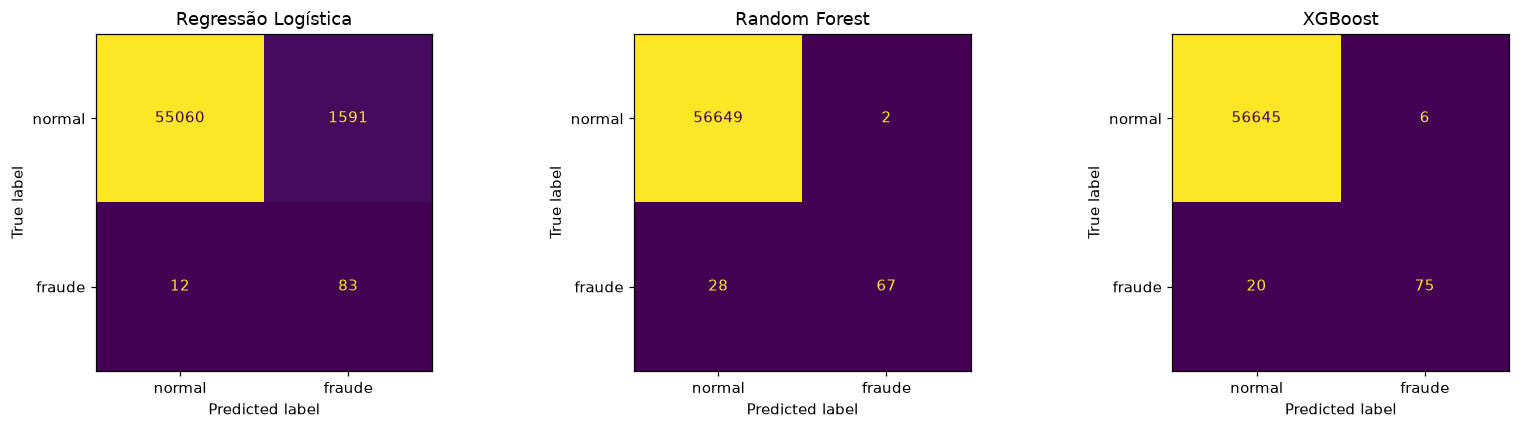

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (nome, proba) in zip(axes, proba_test.items()):
    cm = confusion_matrix(y_test, (proba >= 0.5).astype(int))
    ConfusionMatrixDisplay(cm, display_labels=["normal", "fraude"]).plot(ax=ax, colorbar=False)
    ax.set_title(nome)

plt.tight_layout()
plt.show()

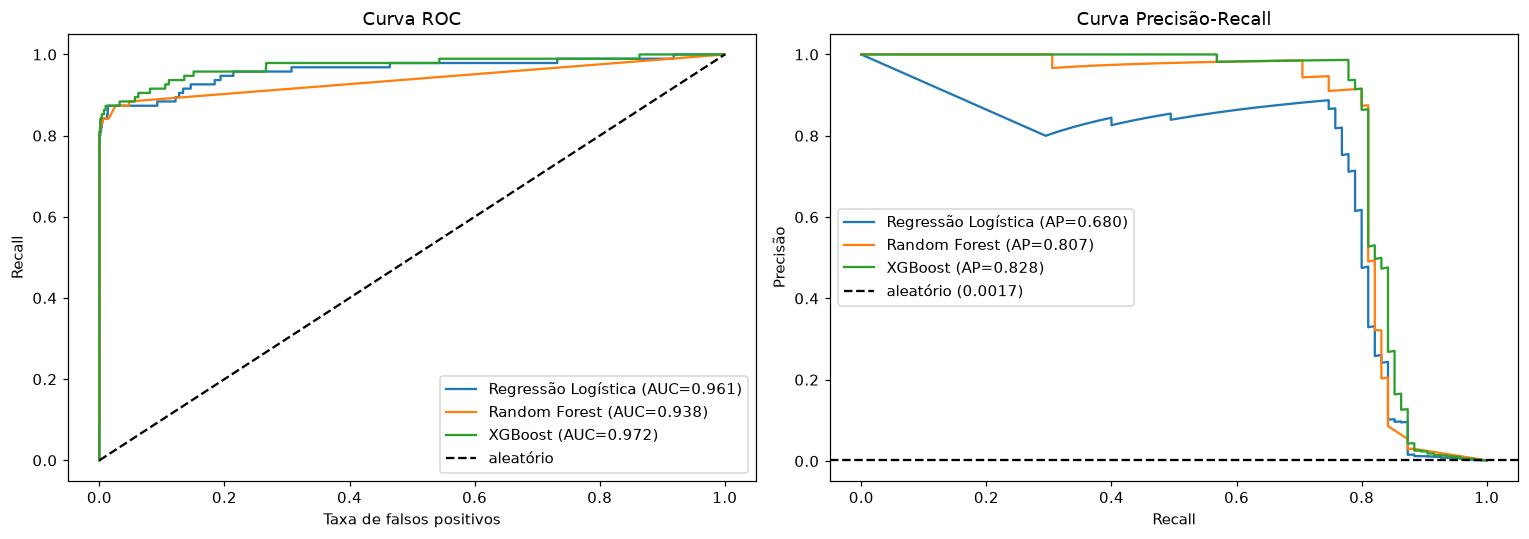

In [37]:
fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(14, 5))

for nome, proba in proba_test.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    ax_roc.plot(fpr, tpr, label=f"{nome} (AUC={roc_auc_score(y_test, proba):.3f})")

    prec, rec, _ = precision_recall_curve(y_test, proba)
    ax_pr.plot(rec, prec, label=f"{nome} (AP={average_precision_score(y_test, proba):.3f})")

ax_roc.plot([0, 1], [0, 1], "k--", label="aleatório")
ax_roc.set(xlabel="Taxa de falsos positivos", ylabel="Recall", title="Curva ROC")

ax_pr.axhline(y_test.mean(), color="k", ls="--", label=f"aleatório ({y_test.mean():.4f})")
ax_pr.set(xlabel="Recall", ylabel="Precisão", title="Curva Precisão-Recall")

ax_roc.legend()
ax_pr.legend()
plt.tight_layout()
plt.show()

In [38]:
def escolher_limiar(y_true, proba, beta=2):
    prec, rec, limiares = precision_recall_curve(y_true, proba)
    prec, rec = prec[:-1], rec[:-1]
    fbeta = (1 + beta**2) * prec * rec / (beta**2 * prec + rec + 1e-12)
    i = np.argmax(fbeta)
    return float(limiares[i]), float(fbeta[i])

limiares = {nome: escolher_limiar(y_val, proba_val[nome])[0] for nome in modelos}
pd.Series(limiares, name="limiar escolhido (validação)")

Regressão Logística   0.9998
Random Forest         0.2197
XGBoost               0.9308
Name: limiar escolhido (validação), dtype: float64

In [39]:
resultados_ajust = pd.DataFrame([avaliar(nome, y_test, proba_test[nome], limiares[nome]) for nome in modelos])

comparacao = pd.concat([
    resultados_05.assign(versão="limiar 0,5"),
    resultados_ajust.assign(versão="limiar ajustado"),
])

comparacao.set_index(["modelo", "versão"])[["limiar", "recall", "precisão", "f1", "pr_auc"]].sort_index()

limiar  recall  precisão     f1  pr_auc
modelo              versão                                                  
Random Forest       limiar 0,5       0.5000  0.7053    0.9710 0.8171  0.8068
                    limiar ajustado  0.2197  0.7789    0.9136 0.8409  0.8068
Regressão Logística limiar 0,5       0.5000  0.8737    0.0496 0.0938  0.6796
                    limiar ajustado  0.9998  0.7684    0.7766 0.7725  0.6796
XGBoost             limiar 0,5       0.5000  0.7895    0.9259 0.8523  0.8280
                    limiar ajustado  0.9308  0.7368    0.9859 0.8434  0.8280

**Leitura do ajuste de limiar (conjunto de teste, 95 fraudes):**

| Modelo | Limiar 0,5 | Limiar ajustado | Saldo |
|---|---|---|---|
| Random Forest | 67 pegas, 2 alertas falsos | 74 pegas, 7 alertas falsos | +7 fraudes por +5 alertas |
| Regressão Logística | 83 pegas, 1.591 alertas falsos | 73 pegas, 21 alertas falsos | -10 fraudes, -1.570 alertas |
| XGBoost | 75 pegas, 6 alertas falsos | 70 pegas, 1 alerta falso | -5 fraudes |

- O ajuste **melhorou o Random Forest** (mais fraudes com poucos alertas a mais) e **tornou a Regressão Logística utilizável** (a precisão subiu de 0,05 para 0,78).
- No **XGBoost, o ajuste não generalizou**: o limiar escolhido na validação (0,93) reduziu o recall no teste. A validação tem só 94 fraudes, então o F2 fica quase plano numa faixa larga de limiares e a escolha fica instável.
- O limiar **não** foi reescolhido olhando o teste, para que a avaliação final continue honesta.
- **Melhoria possível:** escolher o limiar com probabilidades de validação cruzada (`cross_val_predict`) em treino + validação, o que daria ~378 fraudes em vez de 94.

In [40]:
def logistica_com(amostrador):
    return ImbPipeline([
        ("scaler", StandardScaler()),
        ("amostragem", amostrador),
        ("modelo", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ])

variantes = {
    "LR + class_weight": modelos["Regressão Logística"],
    "LR + undersampling": logistica_com(RandomUnderSampler(random_state=RANDOM_STATE)).fit(X_train, y_train),
    "LR + SMOTE": logistica_com(SMOTE(random_state=RANDOM_STATE)).fit(X_train, y_train),
}

linhas = []
for nome, modelo in variantes.items():
    pv = modelo.predict_proba(X_val)[:, 1]
    pt = modelo.predict_proba(X_test)[:, 1]
    lim = escolher_limiar(y_val, pv)[0]
    linhas.append(avaliar(nome, y_test, pt, 0.5) | {"versão": "limiar 0,5"})
    linhas.append(avaliar(nome, y_test, pt, lim) | {"versão": "limiar ajustado"})

pd.DataFrame(linhas).set_index(["modelo", "versão"])[["limiar", "recall", "precisão", "f1", "pr_auc"]]

limiar  recall  precisão     f1  pr_auc
modelo             versão                                                  
LR + class_weight  limiar 0,5       0.5000  0.8737    0.0496 0.0938  0.6796
                   limiar ajustado  0.9998  0.7684    0.7766 0.7725  0.6796
LR + undersampling limiar 0,5       0.5000  0.8632    0.0255 0.0496  0.3229
                   limiar ajustado  0.9988  0.6000    0.3373 0.4318  0.3229
LR + SMOTE         limiar 0,5       0.5000  0.8737    0.0448 0.0852  0.6807
                   limiar ajustado  0.9999  0.7684    0.7849 0.7766  0.6807

In [41]:
grade = {
    "max_depth": [3, 5],
    "learning_rate": [0.05, 0.1],
    "n_estimators": [200, 400],
}

busca = GridSearchCV(
    XGBClassifier(subsample=0.8, colsample_bytree=0.8, scale_pos_weight=peso_fraude,
                  eval_metric="aucpr", tree_method="hist", n_jobs=-1,
                  random_state=RANDOM_STATE),
    param_grid=grade,
    scoring="average_precision",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
)
busca.fit(X_train, y_train)

print("Melhores parâmetros:", busca.best_params_)
print(f"PR-AUC média na validação cruzada: {busca.best_score_:.4f}")

xgb_otimizado = busca.best_estimator_
proba_val["XGBoost otimizado"] = xgb_otimizado.predict_proba(X_val)[:, 1]
proba_test["XGBoost otimizado"] = xgb_otimizado.predict_proba(X_test)[:, 1]
limiares["XGBoost otimizado"] = escolher_limiar(y_val, proba_val["XGBoost otimizado"])[0]

Melhores parâmetros: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 400}
PR-AUC média na validação cruzada: 0.8400


F2 na validação: {'Random Forest': 0.8761, 'XGBoost': 0.8696, 'XGBoost otimizado': 0.8766}

Modelo final: XGBoost otimizado | limiar: 0.6733

              precision    recall  f1-score   support

      normal     0.9996    1.0000    0.9998     56651
      fraude     0.9730    0.7579    0.8521        95

    accuracy                         0.9996     56746
   macro avg     0.9863    0.8789    0.9259     56746
weighted avg     0.9995    0.9996    0.9995     56746



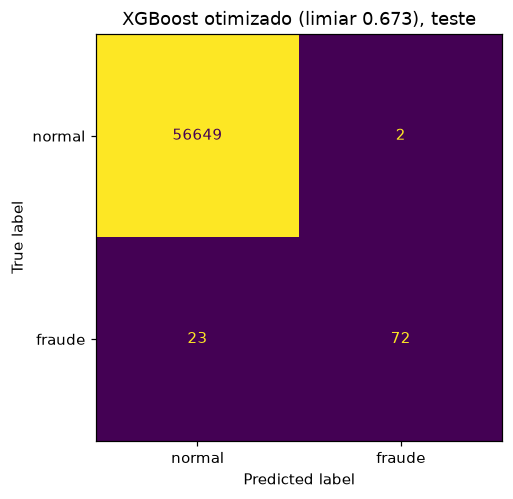

In [42]:
candidatos = {
    "Random Forest": modelos["Random Forest"],
    "XGBoost": modelos["XGBoost"],
    "XGBoost otimizado": xgb_otimizado,
}

f2_val = {nome: escolher_limiar(y_val, proba_val[nome])[1] for nome in candidatos}
nome_final = max(f2_val, key=f2_val.get)
modelo_final = candidatos[nome_final]
limiar_final = limiares[nome_final]

print("F2 na validação:", {nome: round(valor, 4) for nome, valor in f2_val.items()})
print(f"\nModelo final: {nome_final} | limiar: {limiar_final:.4f}\n")

pred_final = (proba_test[nome_final] >= limiar_final).astype(int)
print(classification_report(y_test, pred_final, target_names=["normal", "fraude"], digits=4))

ConfusionMatrixDisplay(confusion_matrix(y_test, pred_final),
                       display_labels=["normal", "fraude"]).plot(colorbar=False)
plt.title(f"{nome_final} (limiar {limiar_final:.3f}), teste")
plt.show()


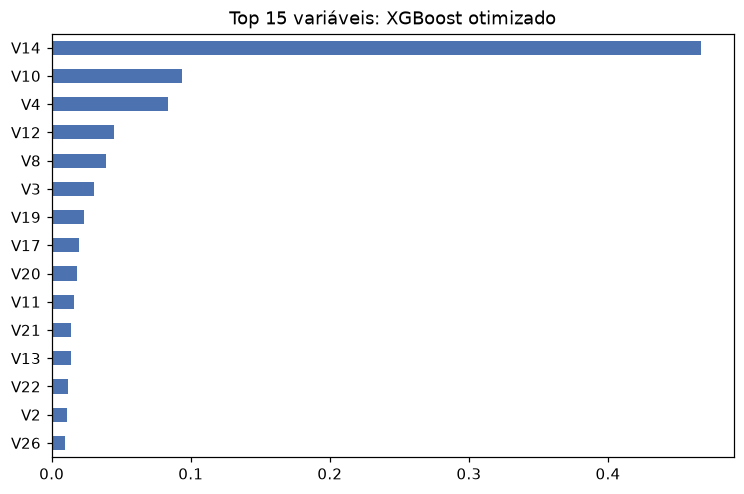

In [43]:
importancia = pd.Series(modelo_final.feature_importances_, index=X.columns).sort_values()

importancia.tail(15).plot.barh(figsize=(8, 5), color="#4C72B0")
plt.title(f"Top 15 variáveis: {nome_final}")
plt.show()

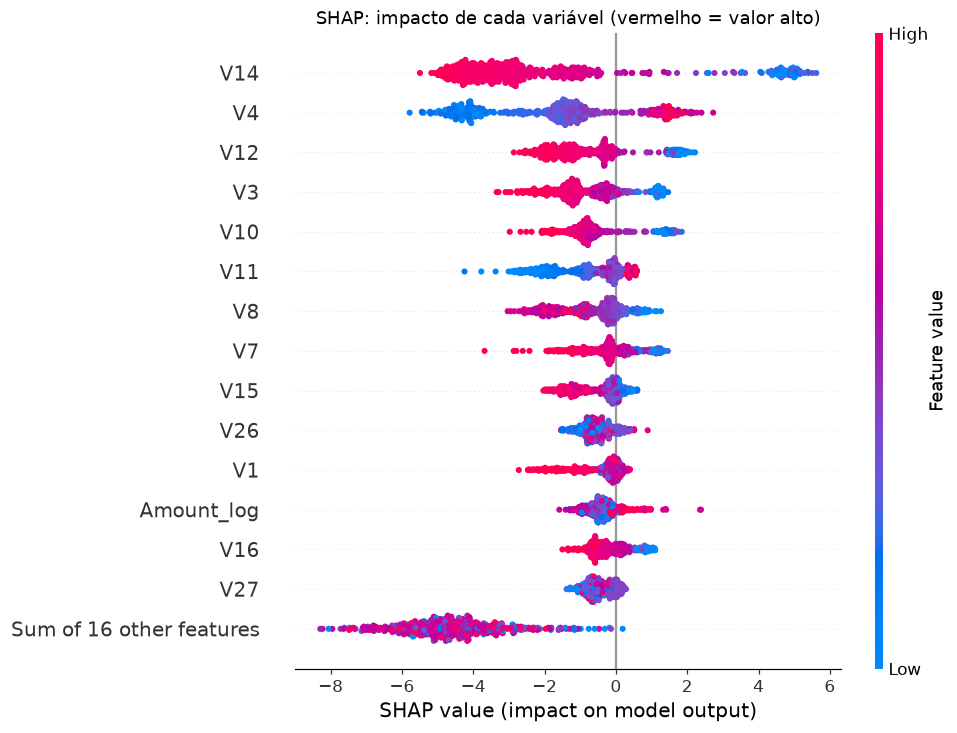

In [44]:
amostra = pd.concat([
    X_test[y_test == 1],
    X_test[y_test == 0].sample(500, random_state=RANDOM_STATE),
])

explainer = shap.TreeExplainer(modelo_final)
sv = explainer(amostra)

shap.plots.beeswarm(sv, max_display=15, show=False)
plt.title("SHAP: impacto de cada variável (vermelho = valor alto)")
plt.show()

Fraude DETECTADA | probabilidade = 1.0000


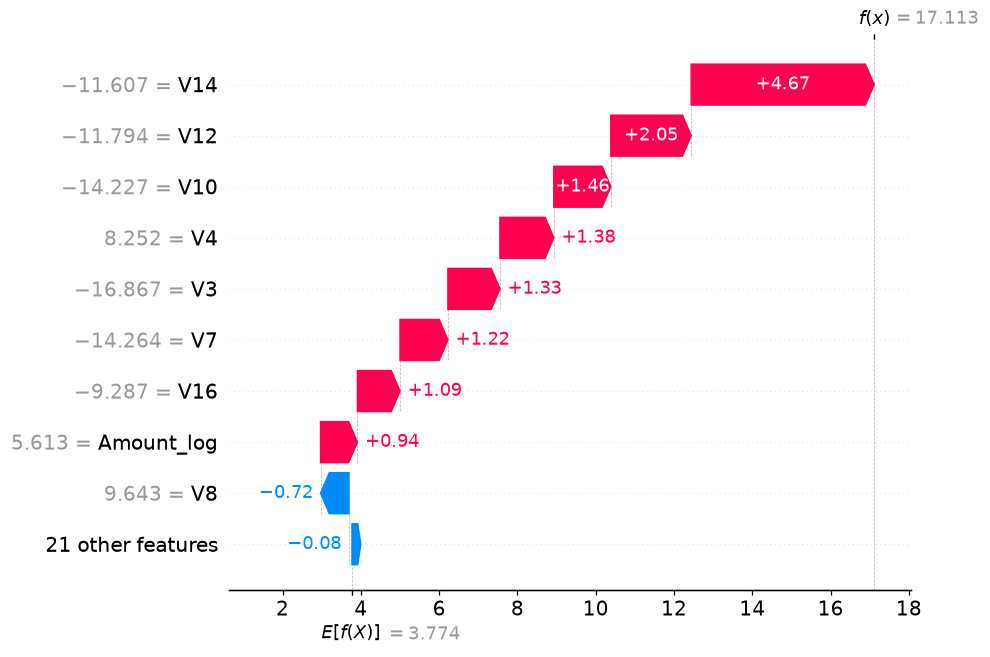

Fraude NÃO detectada | probabilidade = 0.5157 (limiar 0.6733)


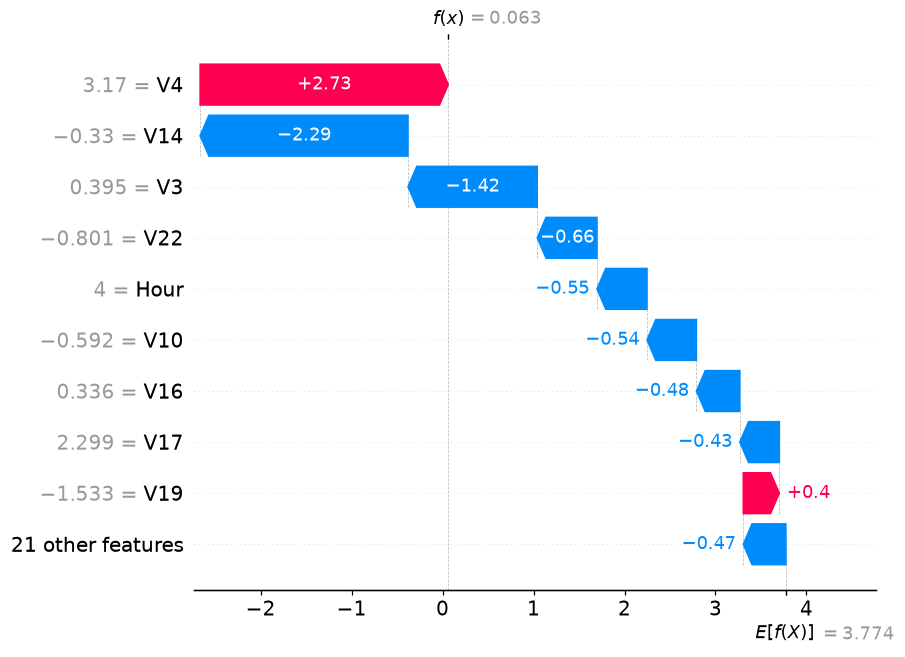

In [45]:
proba_amostra = modelo_final.predict_proba(amostra)[:, 1]
eh_fraude = (y_test.loc[amostra.index] == 1).values

i_acerto = np.where(eh_fraude)[0][np.argmax(proba_amostra[eh_fraude])]
print(f"Fraude DETECTADA | probabilidade = {proba_amostra[i_acerto]:.4f}")
shap.plots.waterfall(sv[i_acerto], max_display=10)

perdidas = np.where(eh_fraude & (proba_amostra < limiar_final))[0]
i_erro = perdidas[np.argmax(proba_amostra[perdidas])]
print(f"Fraude NÃO detectada | probabilidade = {proba_amostra[i_erro]:.4f} (limiar {limiar_final:.4f})")
shap.plots.waterfall(sv[i_erro], max_display=10)

In [ ]:
average_precision_score(y_test, proba_test["XGBoost otimizado"])